# Análise exploratória: óbitos por lesão autoprovocada no Brasil (2014–2018)

**Fonte:** SIM/DataSUS via Kaggle (psicodata). **Pré-requisito:** rodar `python -m src.etl` na raiz do repositório.

**Perguntas de pesquisa** (ajuste conforme a versão aprovada pelo docente):

1. **RQ1:** como evoluíram os óbitos por ano, região e UF?
2. **RQ2:** qual o perfil por sexo, faixa etária, escolaridade, raça/cor e estado civil?
3. **RQ3:** há padrão sazonal (mês) ou por local de ocorrência e meio utilizado?

> Os dados tratam de mortes e devem ser lidos com respeito. Todas as análises usam **contagens**; comparar grupos ou locais com populações diferentes exige taxas (ver a seção opcional da RQ1).

## 0. Configuração

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ASSETS = RAIZ / "docs" / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})

NAO = "Não informado"
FAIXAS = ["0-9", "10-14", "15-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
ESCOLARIDADE = ["Nenhuma", "1 a 3 anos", "4 a 7 anos", "8 a 11 anos", "12 e mais"]
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
exportados = []


def salvar(fig, nome):
    """Salva a figura estática (PNG) em docs/assets/ para uso no artigo."""
    fig.savefig(ASSETS / f"{nome}.png", bbox_inches="tight")
    exportados.append(f"{nome}.png")


def salvar_html(fig, nome):
    """Salva a figura interativa (Plotly) em docs/assets/, para incorporar via <iframe>."""
    fig.write_html(ASSETS / f"{nome}.html", include_plotlyjs="cdn")
    exportados.append(f"{nome}.html")

## 1. Carga e qualidade dos dados

In [2]:
df = pd.read_parquet(RAIZ / "data" / "processed" / "suicidios_2014_2018.parquet")

# Recorte da análise: causas básicas X60–X84 (CID-10, lesões autoprovocadas)
d = df[df["lesao_autoprovocada"]].copy()
d["idade_f"] = d["idade"].astype("float")

print(f"Registros na base tratada: {len(df):,}".replace(",", "."))
print(f"Registros no recorte X60–X84: {len(d):,} ({len(d) / len(df):.2%})".replace(",", "."))
print(f"Período: {d['ano'].min()} a {d['ano'].max()} | UFs: {d['uf'].nunique()}")
d.head()

Registros na base tratada: 58.634
Registros no recorte X60–X84: 58.492 (99.76%)
Período: 2014 a 2018 | UFs: 27


,uf,ano,circunstancia_obito,data_obito,data_nascimento,sexo,raca_cor,estado_civil,escolaridade,ocupacao,...,causa_basica_original,idade,mes,flag_data_inconsistente,flag_idade_invalida,faixa_etaria,regiao,meio_utilizado,lesao_autoprovocada,idade_f
0,AC,2014,Suicídio,2014-01-02,1977-07-02,Masculino,Preta,Casado,4 a 7 anos,ATLETA PROFISSIONAL DE FUTEBOL,...,X700,37,1,False,False,30-39,Norte,Enforcamento/sufocação,True,37.0
1,AC,2014,Suicídio,2014-01-23,1966-07-30,Masculino,Branca,União consensual,12 e mais,MEDICO GINECOLOGISTA E OBSTETRA,...,X800,48,1,False,False,40-49,Norte,Precipitação de lugar elevado,True,48.0
2,AC,2014,Suicídio,2014-01-31,1943-07-28,Masculino,Branca,Não informado,Não informado,Não informado,...,X700,71,1,False,False,70-79,Norte,Enforcamento/sufocação,True,71.0
3,AC,2014,Suicídio,2014-02-05,1999-07-04,Masculino,Branca,Solteiro,4 a 7 anos,ESTUDANTE,...,X700,15,2,False,False,15-19,Norte,Enforcamento/sufocação,True,15.0
4,AC,2014,Suicídio,2014-02-06,1972-05-02,Masculino,Branca,Não informado,Não informado,Não informado,...,X700,42,2,False,False,40-49,Norte,Enforcamento/sufocação,True,42.0


sexo                    0.0
local_ocorrencia        0.3
raca_cor                2.3
circunstancia_obito     3.4
estado_civil            7.4
ocupacao               21.1
escolaridade           23.0
assistencia_medica     30.3

Idade ausente: 228 registros


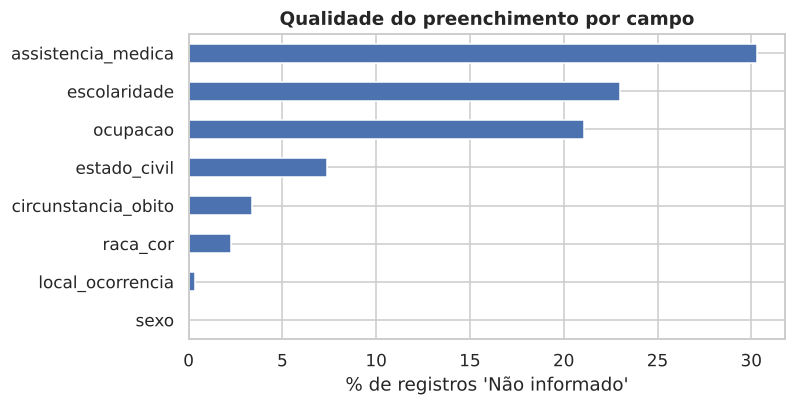

In [3]:
cols_cat = ["circunstancia_obito", "sexo", "raca_cor", "estado_civil", "escolaridade",
            "ocupacao", "local_ocorrencia", "assistencia_medica"]
nao_inf = (d[cols_cat].eq(NAO).mean() * 100).sort_values()
print(nao_inf.round(1).to_string())
print(f"\nIdade ausente: {d['idade'].isna().sum()} registros")

fig, ax = plt.subplots(figsize=(7, 3.6))
nao_inf.plot.barh(ax=ax, color=sns.color_palette()[0])
ax.set_xlabel("% de registros 'Não informado'")
ax.set_ylabel("")
ax.set_title("Qualidade do preenchimento por campo")
salvar(fig, "qualidade_nao_informado")
plt.show()

**Leitura:** campos como assistência médica, escolaridade e ocupação têm muita informação ausente. Nas seções seguintes, os percentuais desses campos são calculados **sem** os registros "Não informado", e a parcela excluída é sempre indicada.

## 2. RQ1: evolução por ano, região e UF

,obitos,var_pct_ano_anterior
ano,,
2014,10653,NaN
2015,11178,4.9
2016,11433,2.3
2017,12495,9.3
2018,12733,1.9


Variação 2014 → 2018: +19.5%


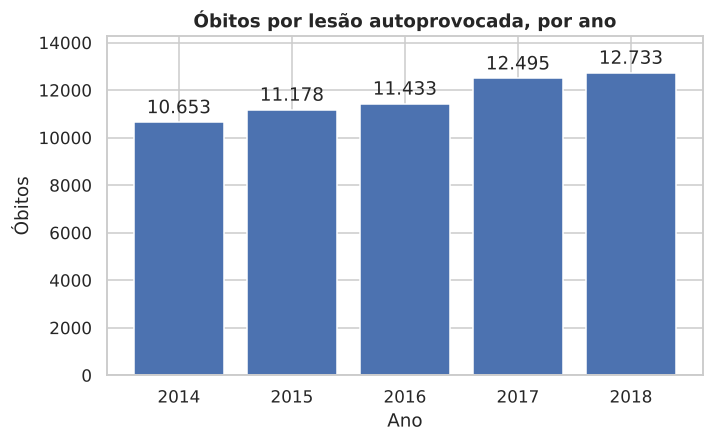

In [4]:
por_ano = d.groupby("ano").size().rename("obitos").to_frame()
por_ano["var_pct_ano_anterior"] = por_ano["obitos"].pct_change() * 100
var_total = (por_ano["obitos"].iloc[-1] / por_ano["obitos"].iloc[0] - 1) * 100
display(por_ano.round(1))
print(f"Variação 2014 → 2018: {var_total:+.1f}%")

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(por_ano.index.astype(str), por_ano["obitos"], color=sns.color_palette()[0])
ax.bar_label(barras, labels=[f"{v:,}".replace(",", ".") for v in por_ano["obitos"]], padding=3)
ax.set_title("Óbitos por lesão autoprovocada, por ano")
ax.set_xlabel("Ano")
ax.set_ylabel("Óbitos")
ax.set_ylim(0, por_ano["obitos"].max() * 1.12)
salvar(fig, "fig1_obitos_por_ano")
plt.show()

In [5]:
reg = d.groupby(["ano", "regiao"]).size().reset_index(name="obitos")
fig = px.line(reg, x="ano", y="obitos", color="regiao", markers=True,
              title="Óbitos por ano e região", labels={"obitos": "Óbitos", "ano": "Ano", "regiao": "Região"})
fig.update_xaxes(dtick=1)
salvar_html(fig, "fig_regiao_ano")
fig.show()

reg_tab = reg.pivot(index="regiao", columns="ano", values="obitos")
reg_tab["var_pct_2014_2018"] = (reg_tab[2018] / reg_tab[2014] - 1) * 100
reg_tab.round(1).sort_values("var_pct_2014_2018", ascending=False)

ano,2014,2015,2016,2017,2018,var_pct_2014_2018
regiao,,,,,,
Norte,708,881,826,896,991,40.0
Nordeste,2393,2540,2722,2981,2996,25.2
Sul,2319,2494,2602,2862,2891,24.7
Centro-Oeste,950,940,1034,1121,1180,24.2
Sudeste,4283,4323,4249,4635,4675,9.2


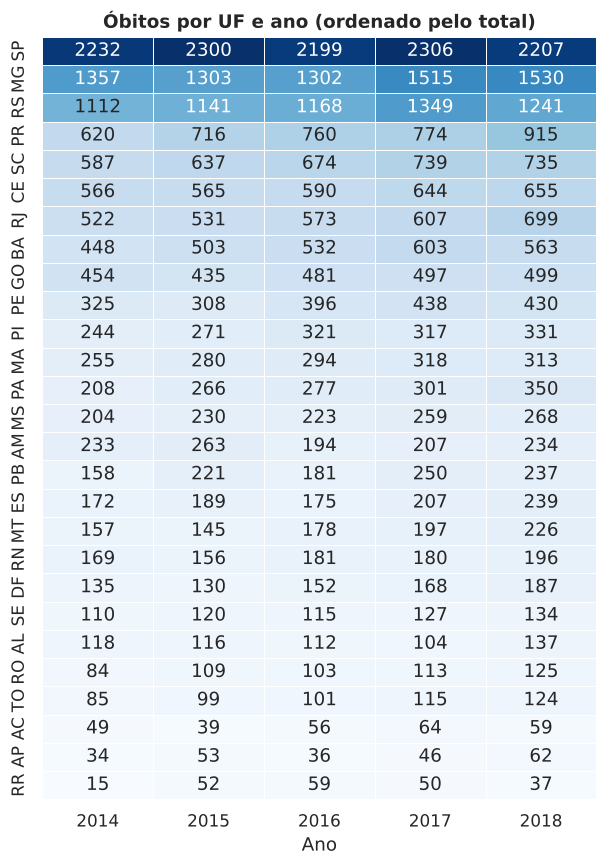

Cinco UFs com mais óbitos no período (contagem absoluta, não taxa):
uf
SP    11244
MG     7007
RS     6011
PR     3785
SC     3372


In [6]:
uf_ano = d.pivot_table(index="uf", columns="ano", values="mes", aggfunc="size", fill_value=0)
uf_ano = uf_ano.loc[uf_ano.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(6.5, 9))
sns.heatmap(uf_ano, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5, ax=ax)
ax.set_title("Óbitos por UF e ano (ordenado pelo total)")
ax.set_xlabel("Ano")
ax.set_ylabel("")
salvar(fig, "fig_uf_ano_heatmap")
plt.show()

total_uf = uf_ano.sum(axis=1)
print("Cinco UFs com mais óbitos no período (contagem absoluta, não taxa):")
print(total_uf.head(5).to_string())

### Taxa por 100 mil habitantes (opcional, recomendado)

Contagens absolutas favorecem UFs populosas. Para comparar UFs com justiça, use a população estimada pelo IBGE.

1. Baixe a população residente por UF e ano (2014 a 2018) no portal do IBGE (projeções ou estimativas da população).
2. Salve em `data/external/populacao_uf.csv` com as colunas `uf,ano,populacao` (veja `populacao_uf_MODELO.csv`).
3. Rode a célula abaixo. Se o arquivo não existir, ela só avisa.

In [7]:
pop_path = RAIZ / "data" / "external" / "populacao_uf.csv"

if pop_path.exists():
    pop = pd.read_csv(pop_path)
    taxa = (d.groupby(["uf", "ano"]).size().rename("obitos").reset_index()
              .merge(pop, on=["uf", "ano"], how="left", validate="one_to_one"))
    assert taxa["populacao"].notna().all(), "Há UF/ano sem população no arquivo externo"
    taxa["taxa_100k"] = taxa["obitos"] / taxa["populacao"] * 100_000

    media = taxa.groupby("uf")["taxa_100k"].mean().sort_values()
    fig, ax = plt.subplots(figsize=(7, 8))
    media.plot.barh(ax=ax, color=sns.color_palette()[0])
    ax.set_xlabel("Taxa média anual por 100 mil habitantes (2014–2018)")
    ax.set_ylabel("")
    ax.set_title("Taxa por UF")
    salvar(fig, "fig_taxa_uf")
    plt.show()
else:
    print(f"Arquivo {pop_path.relative_to(RAIZ)} não encontrado: seção de taxas ignorada.")

Arquivo data/external/populacao_uf.csv não encontrado: seção de taxas ignorada.


## 3. RQ2: perfil das vítimas

In [8]:
sexo = d[d["sexo"] != NAO]
tab = sexo.groupby(["ano", "sexo"]).size().unstack()
tab["razao_homens_por_mulher"] = tab["Masculino"] / tab["Feminino"]
tab["pct_masculino"] = tab["Masculino"] / (tab["Masculino"] + tab["Feminino"]) * 100
display(tab.round(2))
print(f"Sexo não informado: {(d['sexo'] == NAO).sum()} registros (excluídos desta tabela)")

sexo,Feminino,Masculino,razao_homens_por_mulher,pct_masculino
ano,,,,
2014,2233,8419,3.77,79.04
2015,2396,8780,3.66,78.56
2016,2378,9053,3.81,79.20
2017,2664,9826,3.69,78.67
2018,2729,9999,3.66,78.56


Sexo não informado: 15 registros (excluídos desta tabela)


sexo,Feminino,Masculino,razao_h_m
faixa_etaria,,,
0-9,5,14,2.80
10-14,269,310,1.15
15-19,1115,2473,2.22
20-29,2090,9341,4.47
30-39,2469,9920,4.02
40-49,2320,8401,3.62
50-59,2074,7037,3.39
60-69,1221,4441,3.64
70-79,584,2681,4.59


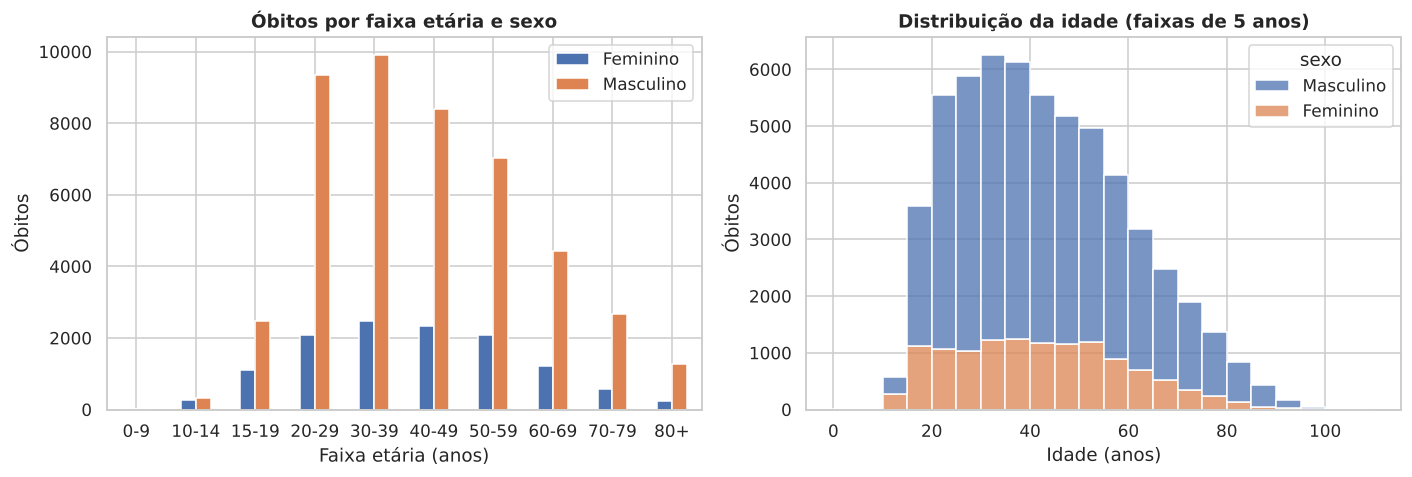

Idade: mediana 40 | média 42.6 anos
sexo
Feminino     41.0
Masculino    40.0


In [9]:
fx = (sexo[sexo["faixa_etaria"] != NAO]
      .groupby(["faixa_etaria", "sexo"]).size().unstack().reindex(FAIXAS))
fx["razao_h_m"] = fx["Masculino"] / fx["Feminino"]
display(fx.round(2))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
fx[["Feminino", "Masculino"]].plot.bar(ax=axs[0], rot=0)
axs[0].set_title("Óbitos por faixa etária e sexo")
axs[0].set_xlabel("Faixa etária (anos)")
axs[0].set_ylabel("Óbitos")
axs[0].legend(title="")

sns.histplot(data=sexo, x="idade_f", hue="sexo", bins=range(0, 111, 5), multiple="stack", ax=axs[1])
axs[1].set_title("Distribuição da idade (faixas de 5 anos)")
axs[1].set_xlabel("Idade (anos)")
axs[1].set_ylabel("Óbitos")
fig.tight_layout()
salvar(fig, "fig_faixa_etaria_sexo")
plt.show()

print(f"Idade: mediana {d['idade_f'].median():.0f} | média {d['idade_f'].mean():.1f} anos")
print(d.groupby("sexo")["idade_f"].median().drop(NAO, errors="ignore").rename("mediana por sexo").to_string())

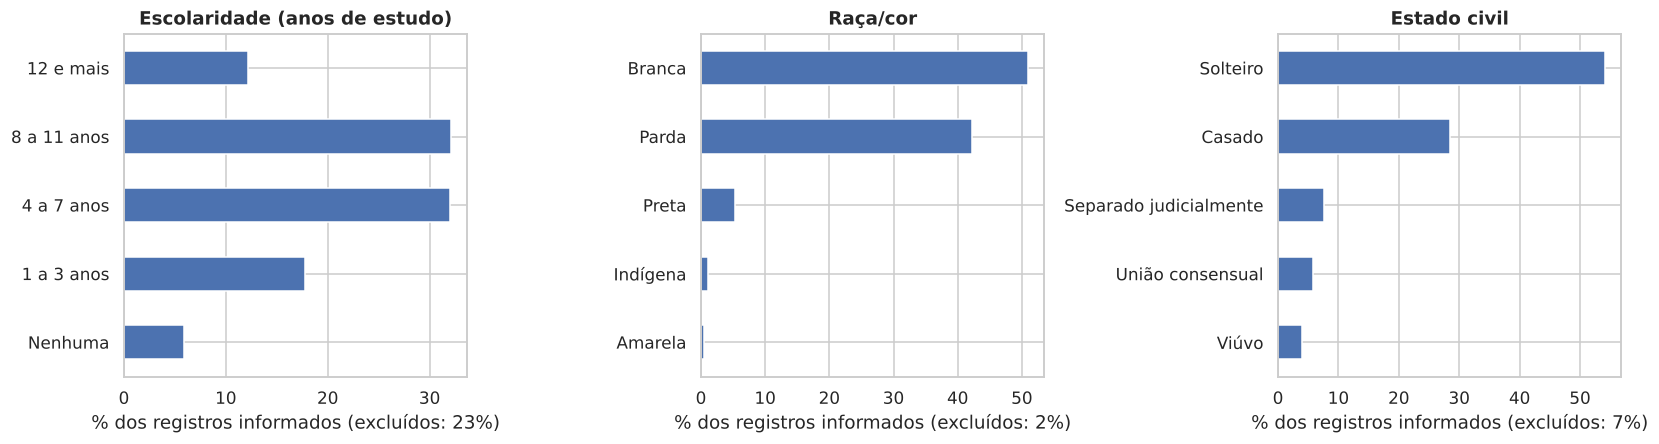

In [10]:
def distribuicao(coluna, ordem=None):
    """Percentual por categoria, sem 'Não informado'. Retorna a série e a parcela excluída."""
    base = d[d[coluna] != NAO]
    s = base[coluna].value_counts(normalize=True) * 100
    if ordem is not None:
        s = s.reindex(ordem)
    else:
        s = s.sort_values()
    return s, 1 - len(base) / len(d)


campos = [("escolaridade", "Escolaridade (anos de estudo)", ESCOLARIDADE),
          ("raca_cor", "Raça/cor", None),
          ("estado_civil", "Estado civil", None)]

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (col, titulo, ordem) in zip(axs, campos):
    s, excl = distribuicao(col, ordem)
    s.plot.barh(ax=ax, color=sns.color_palette()[0])
    ax.set_title(titulo)
    ax.set_xlabel(f"% dos registros informados (excluídos: {excl:.0%})")
    ax.set_ylabel("")
fig.tight_layout()
salvar(fig, "fig_perfil_sociodemografico")
plt.show()

**Cuidado de interpretação:** os percentuais acima mostram a **composição dos óbitos**, não o risco de cada grupo. Para dizer que um grupo tem maior risco, seria preciso dividir pelo tamanho da população desse grupo.

## 4. RQ3: sazonalidade, local de ocorrência e meio utilizado

Qui-quadrado = 143.6 | gl = 11 | p = 3.05e-25
Índice sazonal: máximo 1.07 (mês 12), mínimo 0.91 (mês 7)


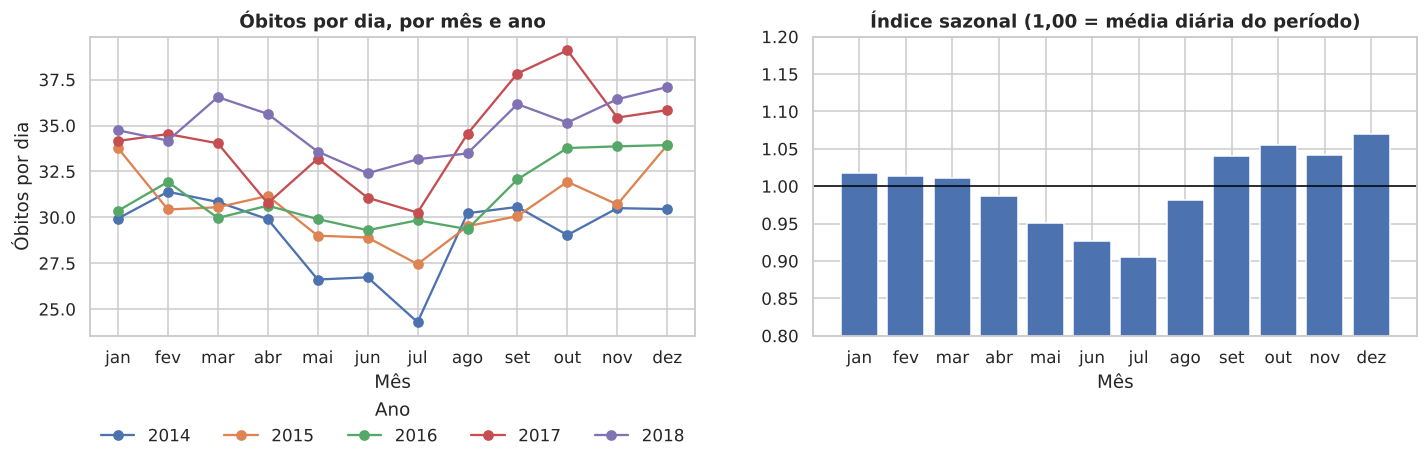

In [11]:
mensal = d.groupby(["ano", "mes"]).size().rename("obitos").reset_index()
mensal["dias"] = [pd.Period(f"{a}-{m:02d}").days_in_month for a, m in zip(mensal["ano"], mensal["mes"])]
mensal["obitos_por_dia"] = mensal["obitos"] / mensal["dias"]

# Teste qui-quadrado: os óbitos se distribuem proporcionalmente aos dias de cada mês?
obs = d.groupby("mes").size()
dias = mensal.groupby("mes")["dias"].sum()
esperado = dias / dias.sum() * obs.sum()
chi = stats.chisquare(obs, f_exp=esperado)
indice = (obs / dias) / (obs.sum() / dias.sum())   # 1,00 = média diária do período

print(f"Qui-quadrado = {chi.statistic:.1f} | gl = 11 | p = {chi.pvalue:.2e}")
print(f"Índice sazonal: máximo {indice.max():.2f} (mês {indice.idxmax()}), mínimo {indice.min():.2f} (mês {indice.idxmin()})")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ano, g in mensal.groupby("ano"):
    axs[0].plot(g["mes"], g["obitos_por_dia"], marker="o", label=str(ano))
axs[0].set_xticks(range(1, 13), MESES)
axs[0].set_title("Óbitos por dia, por mês e ano")
axs[0].set_xlabel("Mês")
axs[0].set_ylabel("Óbitos por dia")
axs[0].legend(title="Ano", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False)

axs[1].bar(range(1, 13), indice.values, color=sns.color_palette()[0])
axs[1].axhline(1, color="black", linewidth=1)
axs[1].set_xticks(range(1, 13), MESES)
axs[1].set_ylim(0.8, 1.2)
axs[1].set_title("Índice sazonal (1,00 = média diária do período)")
axs[1].set_xlabel("Mês")
fig.tight_layout()
salvar(fig, "fig_sazonalidade")
plt.show()

**Leitura estatística:** com mais de 58 mil registros, até desvios pequenos tornam o teste qui-quadrado significativo. Por isso, o **tamanho do desvio** (o índice sazonal) importa tanto quanto o valor-p ao discutir se a sazonalidade é relevante.

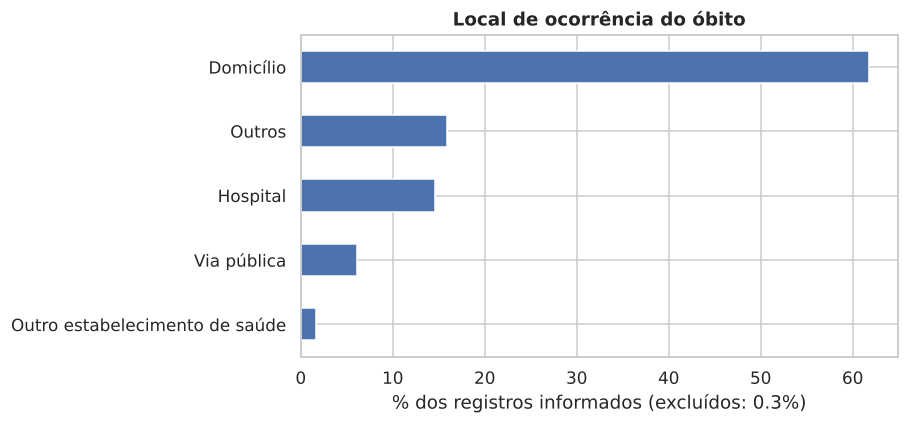

local_ocorrencia
Domicílio                         61.8
Outros                            15.9
Hospital                          14.6
Via pública                        6.1
Outro estabelecimento de saúde     1.6


In [12]:
loc, excl_loc = distribuicao("local_ocorrencia")
fig, ax = plt.subplots(figsize=(7, 3.8))
loc.plot.barh(ax=ax, color=sns.color_palette()[0])
ax.set_xlabel(f"% dos registros informados (excluídos: {excl_loc:.1%})")
ax.set_ylabel("")
ax.set_title("Local de ocorrência do óbito")
salvar(fig, "fig_local_ocorrencia")
plt.show()
print(loc.round(1).sort_values(ascending=False).to_string())

meio_utilizado,Enforcamento/sufocação,Intoxicação/envenenamento,Arma de fogo,Outros meios,Precipitação de lugar elevado,Objeto cortante/contundente,Afogamento
sexo,,,,,,,
Feminino,56.5,22.6,3.9,7.1,6.5,1.7,1.8
Masculino,72.0,8.4,9.3,3.9,3.3,2.3,0.9


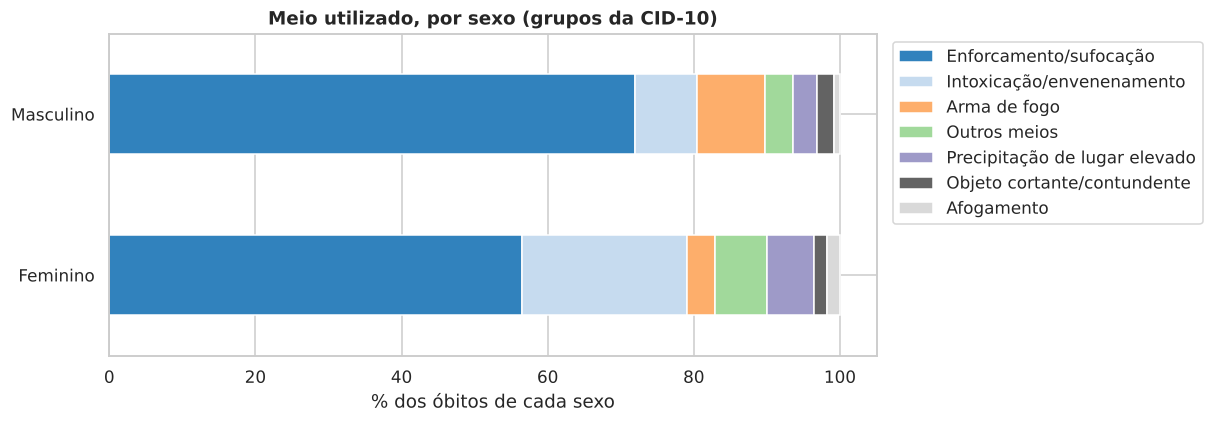

In [13]:
meio = d[(d["sexo"] != NAO)]
cruz = pd.crosstab(meio["sexo"], meio["meio_utilizado"], normalize="index") * 100
ordem_meio = d["meio_utilizado"].value_counts().index
cruz = cruz[ordem_meio]
display(cruz.round(1))

fig, ax = plt.subplots(figsize=(9, 3.8))
cruz.plot.barh(stacked=True, ax=ax, colormap="tab20c")
ax.set_xlabel("% dos óbitos de cada sexo")
ax.set_ylabel("")
ax.set_title("Meio utilizado, por sexo (grupos da CID-10)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", title="")
salvar(fig, "fig_meio_por_sexo")
plt.show()

## 5. Síntese dos achados

In [14]:
pct_m = tab["Masculino"].sum() / (tab["Masculino"].sum() + tab["Feminino"].sum()) * 100
faixa_top = d[d["faixa_etaria"] != NAO]["faixa_etaria"].value_counts().idxmax()
local_top = loc.idxmax()
reg_top = d["regiao"].value_counts().idxmax()

print(f"RQ1  Óbitos {por_ano['obitos'].iloc[0]:,} (2014) → {por_ano['obitos'].iloc[-1]:,} (2018): {var_total:+.1f}%.".replace(",", "."))
print(f"RQ1  Região com mais óbitos (contagem absoluta): {reg_top}.")
print(f"RQ2  Homens: {pct_m:.1f}% dos óbitos com sexo informado; faixa etária mais frequente: {faixa_top} anos.")
print(f"RQ3  Local mais frequente: {local_top} ({loc.max():.1f}% dos informados).")
print(f"RQ3  Índice sazonal entre {indice.min():.2f} e {indice.max():.2f}.")
print("\nFiguras exportadas para docs/assets/:")
for nome in exportados:
    print(" -", nome)

RQ1  Óbitos 10.653 (2014) → 12.733 (2018): +19.5%.
RQ1  Região com mais óbitos (contagem absoluta): Sudeste.
RQ2  Homens: 78.8% dos óbitos com sexo informado; faixa etária mais frequente: 30-39 anos.
RQ3  Local mais frequente: Domicílio (61.8% dos informados).
RQ3  Índice sazonal entre 0.91 e 1.07.

Figuras exportadas para docs/assets/:
 - qualidade_nao_informado.png
 - fig1_obitos_por_ano.png
 - fig_regiao_ano.html
 - fig_uf_ano_heatmap.png
 - fig_faixa_etaria_sexo.png
 - fig_perfil_sociodemografico.png
 - fig_sazonalidade.png
 - fig_local_ocorrencia.png
 - fig_meio_por_sexo.png


### Conclusões (escreva com suas palavras)

- **RQ1:** `[TODO]`
- **RQ2:** `[TODO]`
- **RQ3:** `[TODO]`

**Limitações:** contagens sem população de referência; subnotificação e classificação de causa; campos com muita informação ausente; análise descritiva, sem inferência causal.